# Credit score classification

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import kagglehub
from collections import Counter

from catboost import CatBoostClassifier, Pool
from sklearn.metrics import roc_curve, precision_score, recall_score, auc, f1_score, classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import label_binarize

## Датасет

In [4]:
path = kagglehub.dataset_download("parisrohan/credit-score-classification")
print("Path to dataset files:", path)

Path to dataset files: C:\Users\bvo5\.cache\kagglehub\datasets\parisrohan\credit-score-classification\versions\1


In [5]:
train = pd.read_csv(f'{path}\\train.csv', low_memory=False)
train_copy = train.copy()  

In [6]:
train.head(5)

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0x1602,CUS_0xd40,January,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,_,809.98,26.822620,22 Years and 1 Months,No,49.574949,80.41529543900253,High_spent_Small_value_payments,312.49408867943663,Good
1,0x1603,CUS_0xd40,February,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,31.944960,NaN,No,49.574949,118.28022162236736,Low_spent_Large_value_payments,284.62916249607184,Good
2,0x1604,CUS_0xd40,March,Aaron Maashoh,-500,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,28.609352,22 Years and 3 Months,No,49.574949,81.699521264648,Low_spent_Medium_value_payments,331.2098628537912,Good
3,0x1605,CUS_0xd40,April,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,31.377862,22 Years and 4 Months,No,49.574949,199.4580743910713,Low_spent_Small_value_payments,223.45130972736786,Good
4,0x1606,CUS_0xd40,May,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,Good,809.98,24.797347,22 Years and 5 Months,No,49.574949,41.420153086217326,High_spent_Medium_value_payments,341.48923103222177,Good


In [7]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  object 
 1   Customer_ID               100000 non-null  object 
 2   Month                     100000 non-null  object 
 3   Name                      90015 non-null   object 
 4   Age                       100000 non-null  object 
 5   SSN                       100000 non-null  object 
 6   Occupation                100000 non-null  object 
 7   Annual_Income             100000 non-null  object 
 8   Monthly_Inhand_Salary     84998 non-null   float64
 9   Num_Bank_Accounts         100000 non-null  int64  
 10  Num_Credit_Card           100000 non-null  int64  
 11  Interest_Rate             100000 non-null  int64  
 12  Num_of_Loan               100000 non-null  object 
 13  Type_of_Loan              88592 non-null   ob

Датасет содержит 100000 строк-клиентов и 27 признаков. Некоторые из которых - категориальные, а именно "Month", "Occupation", "Type_of_Loan", "Credit_Mix", "Payment_Behaviour", "Payment_of_Min_Amount". 
Признаки 'ID', 'Customer_ID', 'Name', 'SSN' явл. лишь метаинформацией, которая не участвует в корреляции с целевой переменной, их можно отбросить.
Некоторые столбцы содерждат пропуски, что для бустинга не критично.

In [9]:
train.describe()

,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Delay_from_due_date,Num_Credit_Inquiries,Credit_Utilization_Ratio,Total_EMI_per_month
count,84998.000000,100000.000000,100000.00000,100000.000000,100000.000000,98035.000000,100000.000000,100000.000000
mean,4194.170850,17.091280,22.47443,72.466040,21.068780,27.754251,32.285173,1403.118217
std,3183.686167,117.404834,129.05741,466.422621,14.860104,193.177339,5.116875,8306.041270
min,303.645417,-1.000000,0.00000,1.000000,-5.000000,0.000000,20.000000,0.000000
25%,1625.568229,3.000000,4.00000,8.000000,10.000000,3.000000,28.052567,30.306660
50%,3093.745000,6.000000,5.00000,13.000000,18.000000,6.000000,32.305784,69.249473
75%,5957.448333,7.000000,7.00000,20.000000,28.000000,9.000000,36.496663,161.224249
max,15204.633333,1798.000000,1499.00000,5797.000000,67.000000,2597.000000,50.000000,82331.000000


#### Функция для обработки признака Credit_History_Age, переводит строку в интепретируеморе число
def Credit_History_Age(s=str):
    try:
        y, m = map(int, s[:s.rfind(' ')].split(" Years and "))
        return y + m/12
    except:
        return s

In [11]:
def Credit_History_Age(s=str):
    """
    Переводит строку вида '22 Years and 3 Months' в число (десятичные годы).
    Пример: '22 Years and 3 Months' → 22.25
    """
    try:
        y, m = map(int, s[:s.rfind(' ')].split(" Years and "))
        return y + m / 12
    except Exception:
        return s


In [12]:
#Дропаем признаки, не связанные с целевой переменной 
train = train.drop(columns=['ID', 'Customer_ID', 'Name', 'SSN'])
#Меняем Credit_History_Age
train["Credit_History_Age"] = train["Credit_History_Age"].apply(lambda s: Credit_History_Age(s))

In [13]:
train.head(2)

,Month,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,January,23,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",...,_,809.98,26.82262,22.083333,No,49.574949,80.41529543900253,High_spent_Small_value_payments,312.49408867943663,Good
1,February,23,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",...,Good,809.98,31.94496,NaN,No,49.574949,118.28022162236736,Low_spent_Large_value_payments,284.62916249607184,Good


In [14]:
#Выделяем категориальные признаки
cat_features = ["Month", "Occupation", "Type_of_Loan", "Credit_Mix", "Payment_Behaviour", "Payment_of_Min_Amount"]

In [15]:
# Обработка артефактных значений
# Вместо удаления строк — заменяем артефакты на NaN.
# CatBoost умеет работать с NaN нативно, поэтому строки не теряются.
def replace_artifacts_with_nan(df, columns):
    df = df.copy()
    for col in columns:
        before = df[col].notna().sum()
        df[col] = pd.to_numeric(df[col], errors='coerce')  # артефакты → NaN
        after = df[col].notna().sum()
        print(f"В колонке '{col}' заменено артефактов на NaN: {before - after}")
    return df


В некоторых столбцах, содержащих только числовые значения (float), встречаются артефакты по типу '28_' (string). Нижняя функция чистит датасет от этого, а именно удаляет из него целую строки, если в одном из признаков есть такой артефакт.

In [17]:
for col in train.drop(columns = cat_features).columns:
    try:
        train[col].astype(float)
    except ValueError:
        print(f"Ошибка в столбце: {col}")

Ошибка в столбце: Age
Ошибка в столбце: Annual_Income
Ошибка в столбце: Num_of_Loan
Ошибка в столбце: Num_of_Delayed_Payment
Ошибка в столбце: Changed_Credit_Limit
Ошибка в столбце: Outstanding_Debt
Ошибка в столбце: Amount_invested_monthly
Ошибка в столбце: Monthly_Balance
Ошибка в столбце: Credit_Score


Получены столбцы с артефактами

In [19]:
train = replace_artifacts_with_nan(train, ["Age", "Annual_Income", "Num_of_Loan",
                                             "Num_of_Delayed_Payment", "Changed_Credit_Limit",
                                             "Outstanding_Debt", "Amount_invested_monthly",
                                             "Monthly_Balance"])


В колонке 'Age' заменено артефактов на NaN: 4939
В колонке 'Annual_Income' заменено артефактов на NaN: 6980
В колонке 'Num_of_Loan' заменено артефактов на NaN: 4785
В колонке 'Num_of_Delayed_Payment' заменено артефактов на NaN: 2744
В колонке 'Changed_Credit_Limit' заменено артефактов на NaN: 2091
В колонке 'Outstanding_Debt' заменено артефактов на NaN: 1009
В колонке 'Amount_invested_monthly' заменено артефактов на NaN: 4305
В колонке 'Monthly_Balance' заменено артефактов на NaN: 9


In [20]:
# Превращаем все категориальные признаки в string. NaN станут строками 'nan' (нужно для catboost)
for col in cat_features:
    train[col] = train[col].astype(str)

In [21]:
train.head(2)

,Month,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,January,23.0,Scientist,19114.12,1824.843333,3,4,3,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",...,_,809.98,26.82262,22.083333,No,49.574949,80.415295,High_spent_Small_value_payments,312.494089,Good
1,February,23.0,Scientist,19114.12,NaN,3,4,3,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",...,Good,809.98,31.94496,NaN,No,49.574949,118.280222,Low_spent_Large_value_payments,284.629162,Good


Разбиваем выборку на обучающую и тестовую

In [23]:
y, X = train['Credit_Score'], train.drop('Credit_Score', axis=1)

# stratify=y — гарантирует одинаковое соотношение классов в train и test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


### Корреляционный анализ

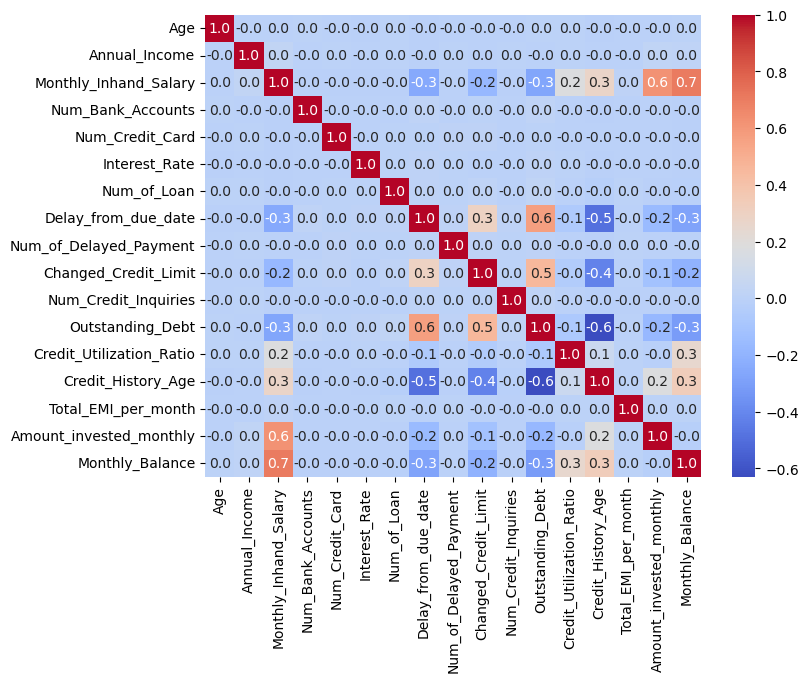

In [25]:
# Смотрим на попарную корреляцию признаков
corr = X_train.drop(columns = cat_features).corr()
# Plot the heatmap
plt.figure(figsize=(8, 6)) # Optional: Adjust figure size
sns.heatmap(corr, cmap='coolwarm', annot=True, fmt=".1f")
plt.show()

По матрице корелляции видно некоторые признаки, которые обладают небольшой линейной связью. Максимальное по модулю значение коэф. корелляции это 0.7 между признаками Monthly_Balance и Monthly_Inhand_Salary. Но его не достаточно, для того, чтобы удалить один из признаков, т.к. потеряется часть полезной информации.

### Распределдение целевой переменной

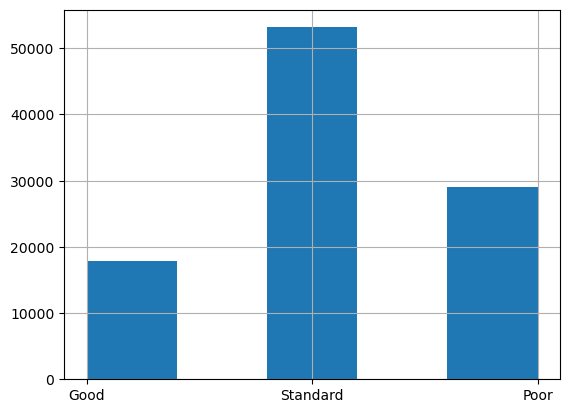

Новый размер датасета: (100000, 23)

Good        17.8%
Standard    53.2%
Poor        29.0%
dtype: object


In [28]:
y.hist(bins = 5)
plt.show()
counter = dict(Counter(y))
print(f"Новый размер датасета: {X.shape}\n")
print(pd.Series({x:f"{(100 * counter[x]/y.count()):.1f}%" for x in counter.keys()}))

После чистки датасета размер таблицы сократился с 75885x23, выборка тем не менее остается репрезентативной. Распределение классов показывает дисбаланс, значит при построении модели следует увеличить штраф за ошибку на классе Poor, он меньше чем Standart.

### Распределдение признаков

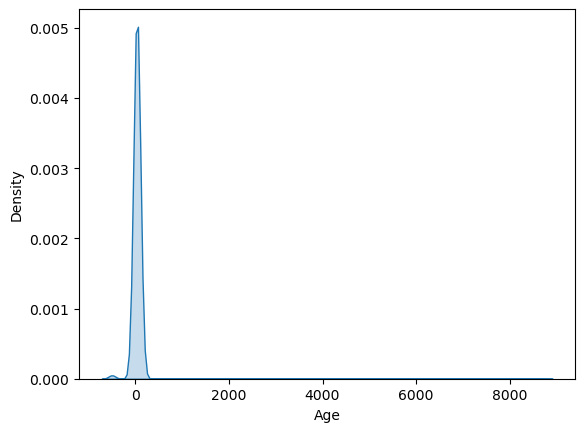

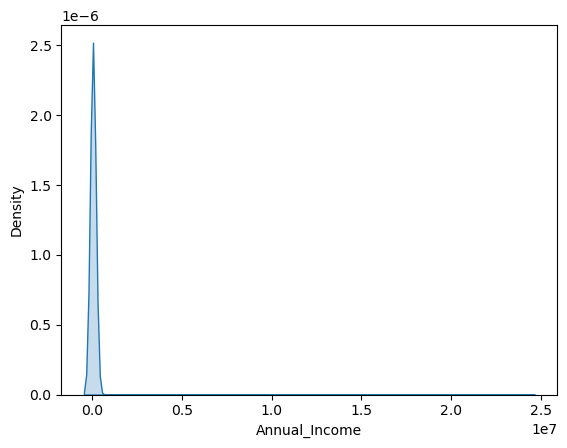

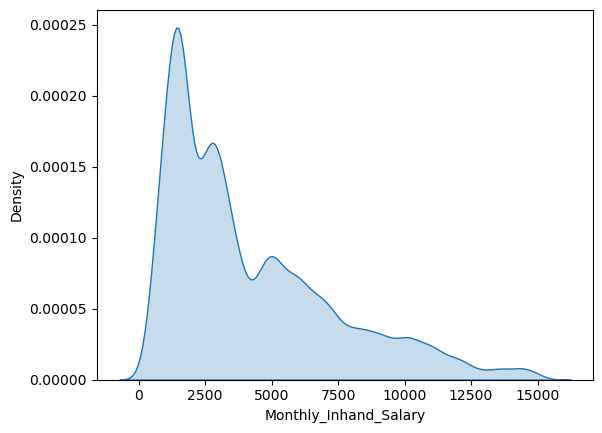

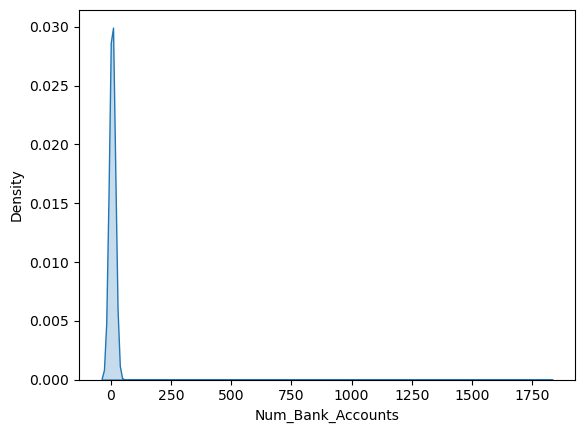

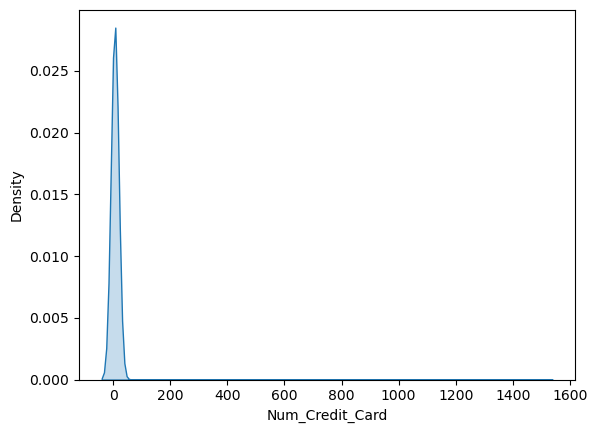

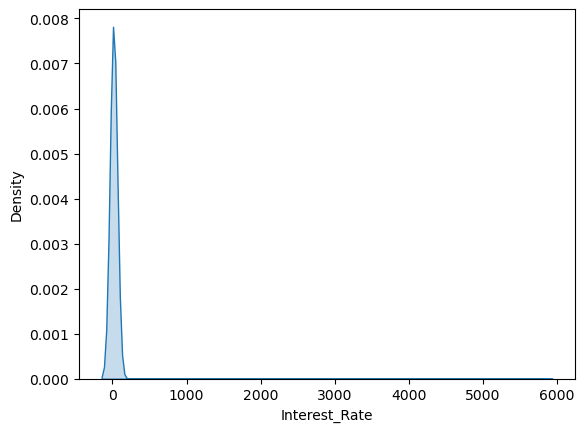

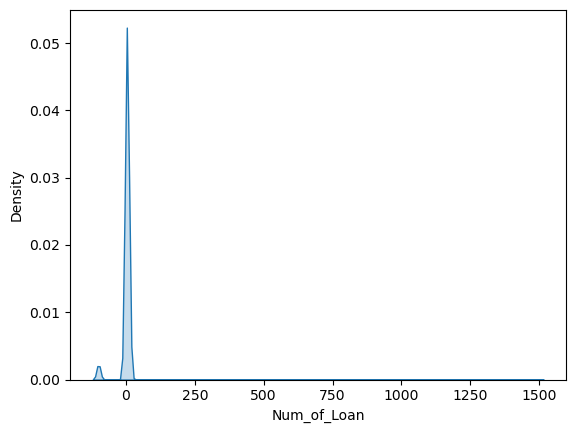

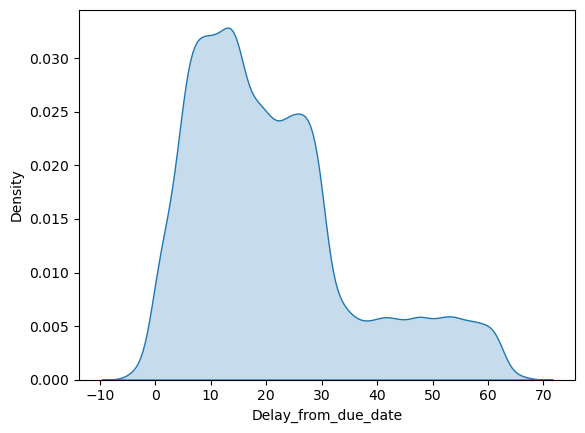

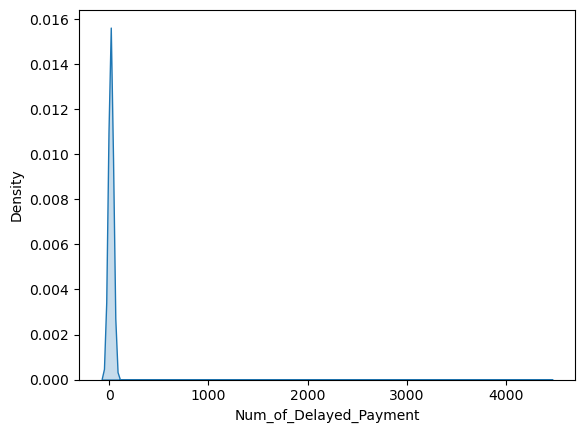

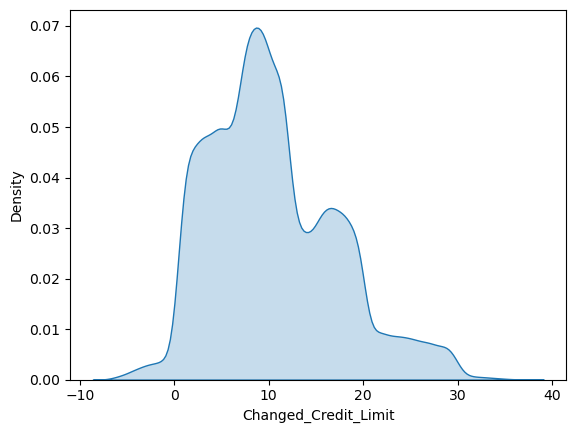

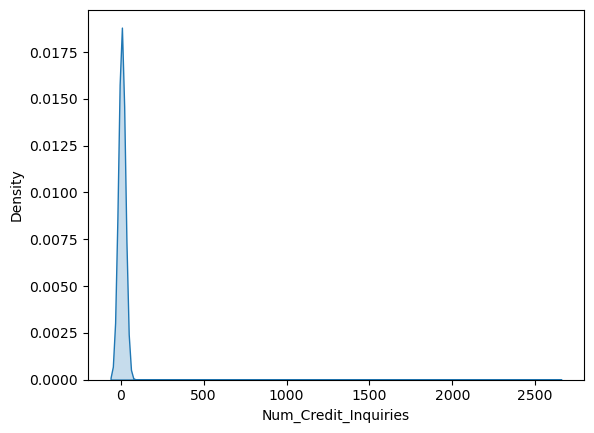

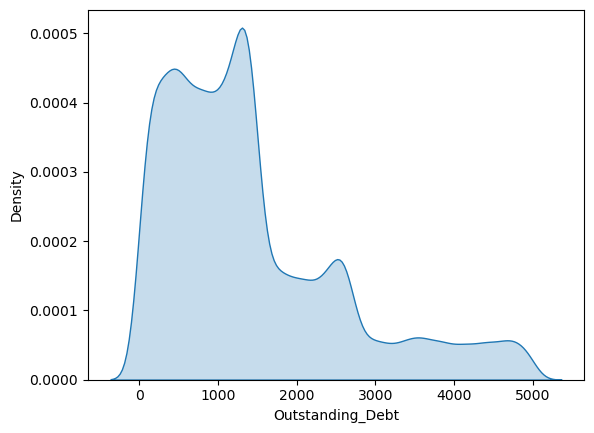

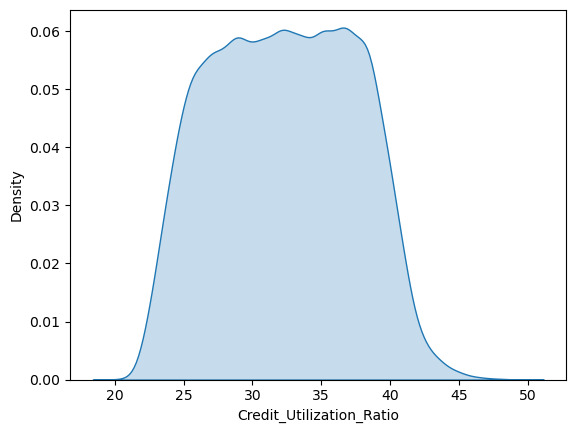

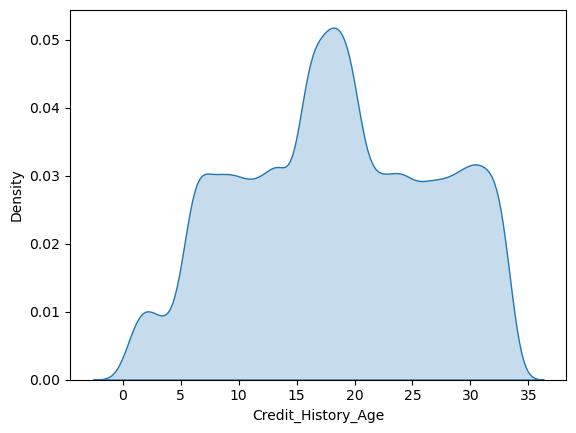

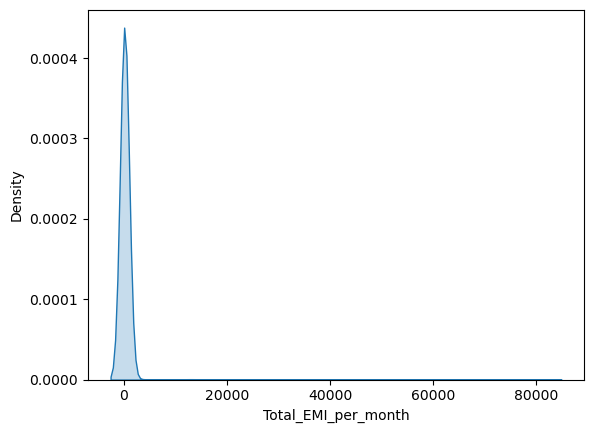

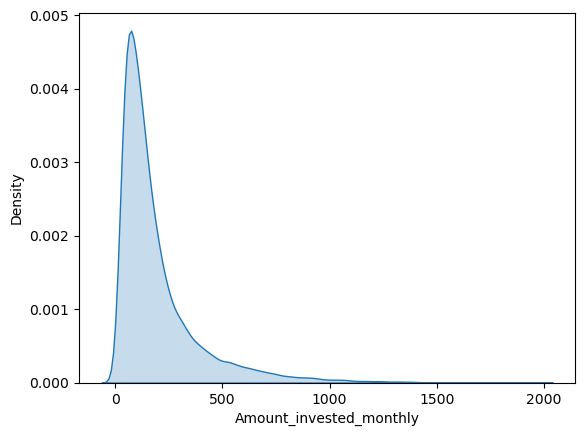

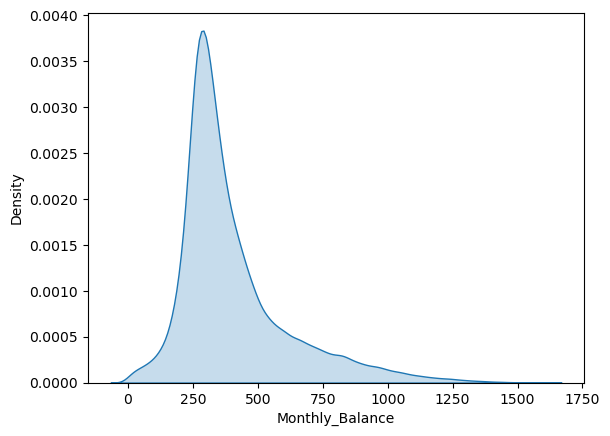

In [31]:
for col in X_train.drop(columns = cat_features).columns:
    sns.kdeplot(X_train[col], fill=True)
    plt.show()

По графикам видно, что некоторые признаки, такие как 'Monthly_Inhand_Salary', 'Delay_from_due_date', 'Amount_invested_monthly', 'Monthly_Balance', имеют распределение, приближенное к логнормальному, то есть горб скошен в левую часть и имеют тяжелый хвост справа. Обучим 2 модели: 1-я будет учиться на всех признаках без изменений, а 2-я - на том же датасете, но с прологарифмированными логнормальными признаками и сравним качество

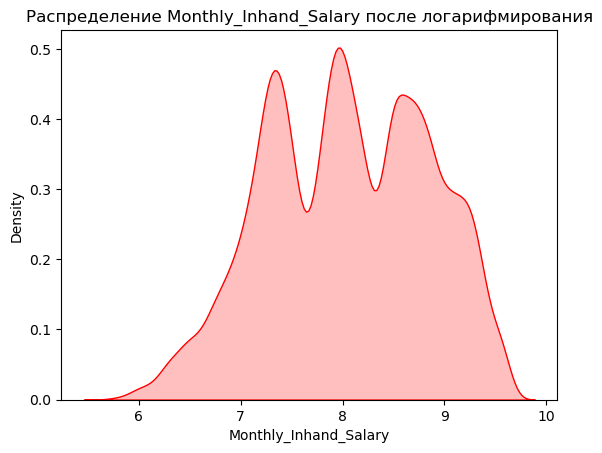

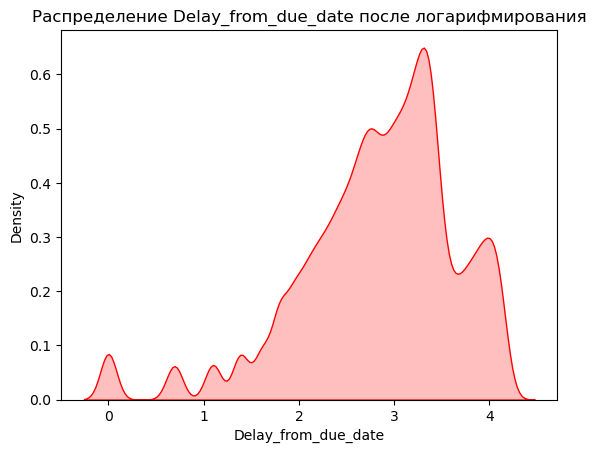

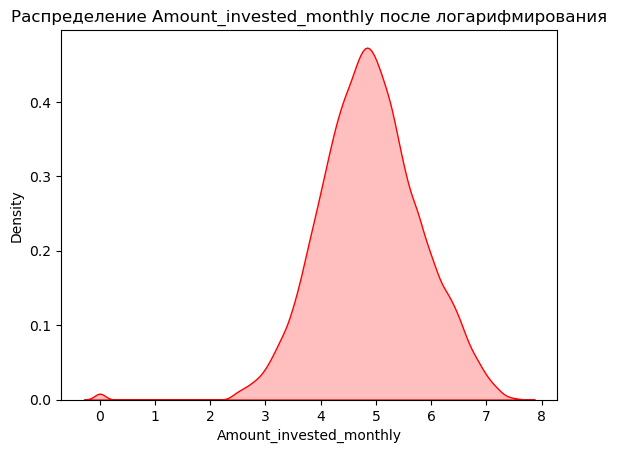

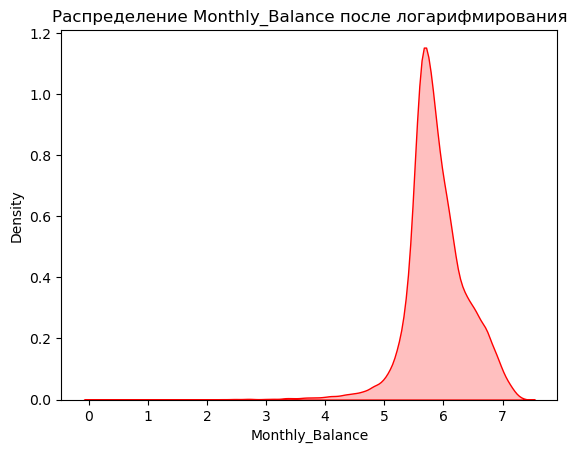

In [33]:
# Логарифмируем признаки с логнормальным распределением.
# clip(lower=0) защищает от -inf при отрицательных значениях (например, Delay_from_due_date=-1)

lognorm_features = ['Monthly_Inhand_Salary', 'Delay_from_due_date', 'Amount_invested_monthly', 'Monthly_Balance']
y_log, X_log = train['Credit_Score'], train.drop('Credit_Score', axis=1)
X_train_log, X_test_log, y_train_log, y_test_log = train_test_split(
    X_log, y_log, test_size=0.2, random_state=42, stratify=y_log)

for col in lognorm_features:
    X_train_log[col] = np.log1p(X_train_log[col].clip(lower=0))
    X_test_log[col]  = np.log1p(X_test_log[col].clip(lower=0))
    sns.kdeplot(X_train_log[col], fill=True, color='red')
    plt.title(f'Распределение {col} после логарифмирования')
    plt.show()


Распределение этих признаков более менее выравнялось, модели будет легче справляться с данными, распределенными нормально.

## Обучение

Попробуем найти лучшие параметры через GridSearchCV

In [37]:
# GridSearchCV уже был запущен ранее. Лучшие параметры использованы в model1/model2 ниже.
# Раскомментируй для повторного поиска гиперпараметров.

# model_gs = CatBoostClassifier(logging_level='Silent', cat_features=cat_features, task_type='GPU')
#
# param_grid = {
#     'depth': [4, 6, 8],
#     'learning_rate': [0.03, 0.06, 0.1, 0.5, 1],
#     'iterations': [100, 150, 200, 500],
#     'class_weights': [[1, 1, 3], [1, 1, 4], [2, 1, 5], [2, 1, 5]]
# }
#
# grid_search = GridSearchCV(
#     estimator=model_gs,
#     param_grid=param_grid,
#     scoring='recall_macro',
#     cv=3
# )
#
# grid_search.fit(X_train, y_train)
# print(f"Лучшие параметры: {grid_search.best_params_}")


In [38]:
model1 = CatBoostClassifier(
    iterations=500,
    learning_rate=0.5,
    depth=8,
    class_weights={'Good': 1, 'Standard': 1, 'Poor': 3},
    cat_features=cat_features,
    verbose=25,
    task_type='GPU'
)

model2 = CatBoostClassifier(
    iterations=500,
    learning_rate=0.5,
    depth=8,
    class_weights={'Good': 1, 'Standard': 1, 'Poor': 3},
    cat_features=cat_features,
    verbose=25,
    task_type='GPU'
)


Создаем два датасета для двух моделей - обычный и частично прологарифмированный

In [40]:
train_data1 = Pool(
    data=X_train, 
    label=y_train, 
    cat_features=cat_features,
)

train_data2 = Pool(
    data=X_train_log, 
    label=y_train_log, 
    cat_features=cat_features,
)
print("Обычное обучение")
model1.fit(train_data1)
print("\n\nОбучение с отлографмированными столбцами")
model2.fit(train_data2)

Обычное обучение
0:	learn: 0.7952934	total: 88.3ms	remaining: 44.1s
25:	learn: 0.4954187	total: 439ms	remaining: 8.01s
50:	learn: 0.4550337	total: 796ms	remaining: 7s
75:	learn: 0.4232836	total: 1.1s	remaining: 6.15s
100:	learn: 0.3976611	total: 1.44s	remaining: 5.7s
125:	learn: 0.3729769	total: 1.79s	remaining: 5.32s
150:	learn: 0.3522469	total: 2.12s	remaining: 4.89s
175:	learn: 0.3363374	total: 2.45s	remaining: 4.52s
200:	learn: 0.3209302	total: 2.78s	remaining: 4.13s
225:	learn: 0.3075207	total: 3.1s	remaining: 3.76s
250:	learn: 0.2925459	total: 3.43s	remaining: 3.4s
275:	learn: 0.2779234	total: 3.76s	remaining: 3.05s
300:	learn: 0.2650145	total: 4.09s	remaining: 2.71s
325:	learn: 0.2524803	total: 4.42s	remaining: 2.36s
350:	learn: 0.2417582	total: 4.76s	remaining: 2.02s
375:	learn: 0.2322299	total: 5.08s	remaining: 1.68s
400:	learn: 0.2217840	total: 5.42s	remaining: 1.34s
425:	learn: 0.2122506	total: 5.75s	remaining: 999ms
450:	learn: 0.2030595	total: 6.23s	remaining: 677ms
475:	l

In [41]:
# Сохраняем обученные модели для дальнейшего использования без переобучения
model1.save_model('model1_catboost.cbm')
model2.save_model('model2_catboost.cbm')
print("Модели сохранены: model1_catboost.cbm, model2_catboost.cbm")


Модели сохранены: model1_catboost.cbm, model2_catboost.cbm


### Feature Importance


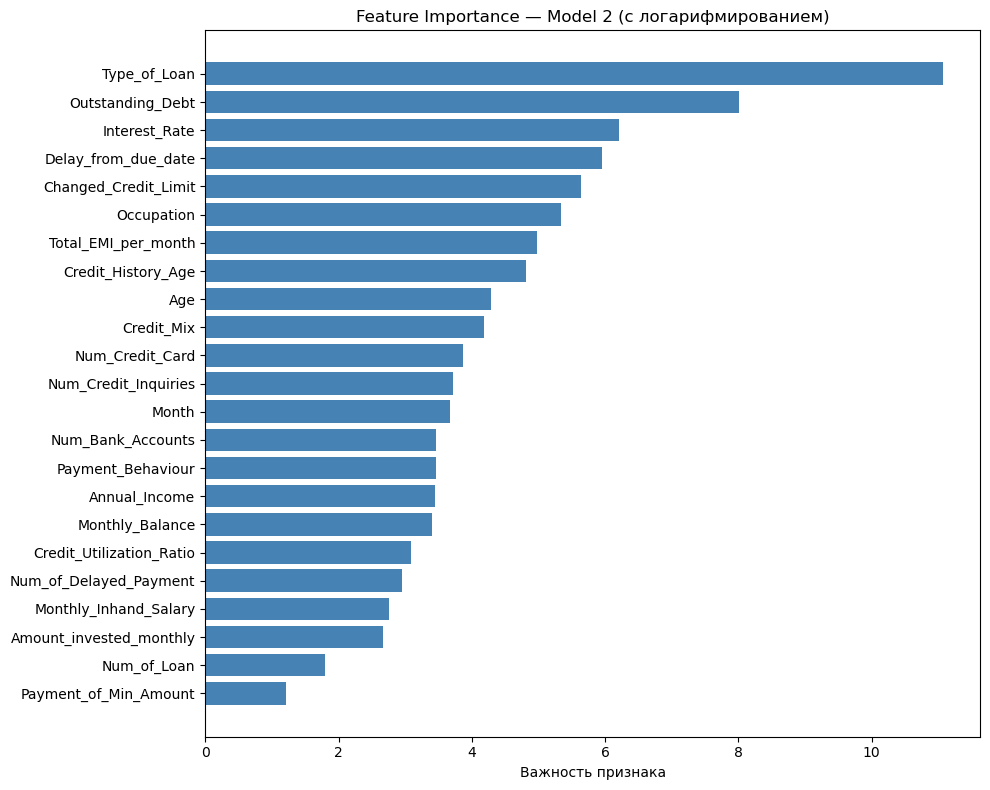

In [43]:
# Feature Importance — какие признаки модель считает наиболее важными
feature_names = X_train_log.columns.tolist()
importances = model2.get_feature_importance()

feat_imp_df = pd.DataFrame({'feature': feature_names, 'importance': importances})
feat_imp_df = feat_imp_df.sort_values('importance', ascending=True)

plt.figure(figsize=(10, 8))
plt.barh(feat_imp_df['feature'], feat_imp_df['importance'], color='steelblue')
plt.xlabel('Важность признака')
plt.title('Feature Importance — Model 2 (с логарифмированием)')
plt.tight_layout()
plt.show()


## Оценка качества

Так как решается задача кредитного скоринга, то будем ставить задачу максимизировать Recall на классе Poor, так как банк не в интересах выдать кредит ненадежному клиенту и в то же время не сильно жертвовать Precision на классе Good. Для каждой модели выведим матрицу ошибок на тестовой выборке, а так-же построим ROC-кривую и посчтаем AUC для тестовой выборки

In [46]:
# Предикты на трейне и тесте
def evaluate(model, X_train, y_train, X_test, y_test):
    classes = ['Good', 'Standard', 'Poor']
    y_pred_test = model.predict(X_test)
    y_proba_test = model.predict_proba(X_test)
    
    y_pred_train = model.predict(X_train)
    y_proba_train = model.predict_proba(X_train)
    
    # Метрики
    print("Accuracy (Train):", accuracy_score(y_train, y_pred_train))
    print("Отчет по классификации (Train):")
    print(classification_report(y_train, y_pred_train), "\n\n")
    
    print("Accuracy (Test):", accuracy_score(y_test, y_pred_test))
    print("Отчет по классификации (Test):")
    print(classification_report(y_test, y_pred_test))
    
    #Матрица ошибок на тесте
    cm = confusion_matrix(y_test, y_pred_test, labels=classes)
    
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=['Good', 'Standard', 'Poor'], 
                yticklabels=['Good', 'Standard', 'Poor'])
    plt.ylabel('Реальные значения')
    plt.xlabel('Предсказания модели')
    plt.title('Матрица ошибок (Confusion Matrix)')
    plt.show()
    print("\n")
    #ROC-AUC
    
    y_test_bin = label_binarize(y_test, classes=classes)
    y_score = model.predict_proba(X_test)
    n_classes = 3
    
    plt.figure(figsize=(10, 7))
    
    for i in range(n_classes):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f'ROC curve {classes[i]} (area = {roc_auc:0.2f})')
    
    plt.plot([0, 1], [0, 1], 'k--', lw=2) 
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Multi-class ROC Curve (CatBoost)')
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.show()

#### Качество первой модели:

Accuracy (Train): 0.9131125
Отчет по классификации (Train):
              precision    recall  f1-score   support

        Good       0.92      0.90      0.91     14262
        Poor       0.84      1.00      0.91     23199
    Standard       0.96      0.87      0.92     42539

    accuracy                           0.91     80000
   macro avg       0.91      0.92      0.91     80000
weighted avg       0.92      0.91      0.91     80000
 


Accuracy (Test): 0.78195
Отчет по классификации (Test):
              precision    recall  f1-score   support

        Good       0.72      0.67      0.69      3566
        Poor       0.74      0.89      0.81      5799
    Standard       0.83      0.76      0.79     10635

    accuracy                           0.78     20000
   macro avg       0.76      0.77      0.77     20000
weighted avg       0.79      0.78      0.78     20000



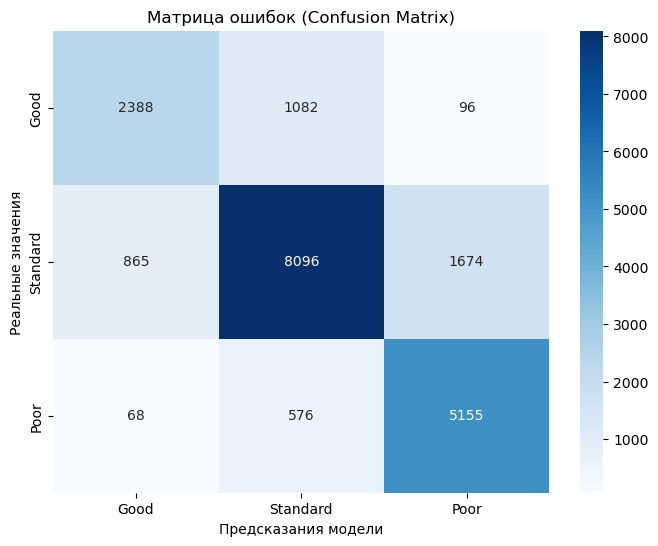

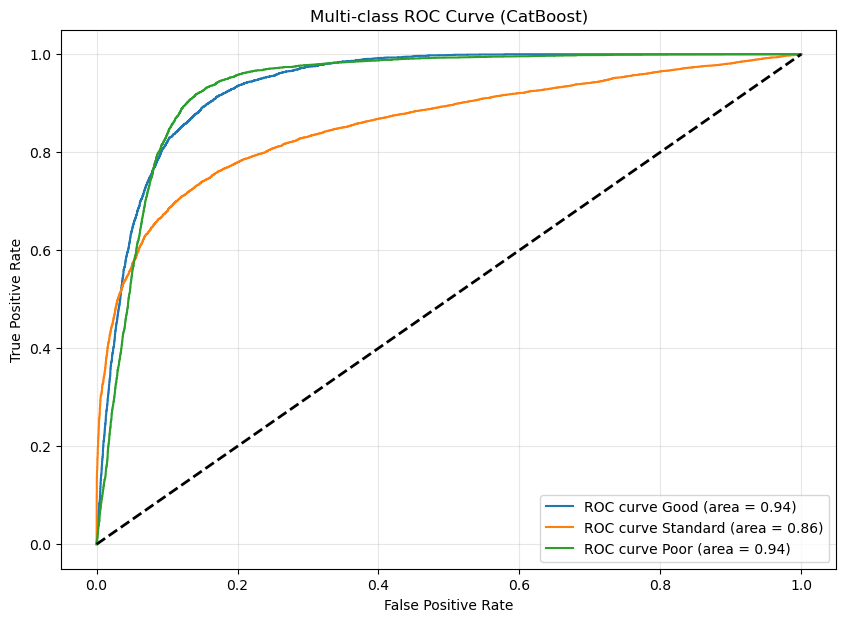

In [48]:
evaluate(model1, X_train, y_train, X_test, y_test)

#### Качество второй модели (с логарифмом):

Accuracy (Train): 0.9135625
Отчет по классификации (Train):
              precision    recall  f1-score   support

        Good       0.92      0.90      0.91     14262
        Poor       0.84      0.99      0.91     23199
    Standard       0.96      0.87      0.92     42539

    accuracy                           0.91     80000
   macro avg       0.91      0.92      0.91     80000
weighted avg       0.92      0.91      0.91     80000
 


Accuracy (Test): 0.78345
Отчет по классификации (Test):
              precision    recall  f1-score   support

        Good       0.72      0.67      0.69      3566
        Poor       0.75      0.89      0.81      5799
    Standard       0.83      0.76      0.80     10635

    accuracy                           0.78     20000
   macro avg       0.77      0.77      0.77     20000
weighted avg       0.79      0.78      0.78     20000



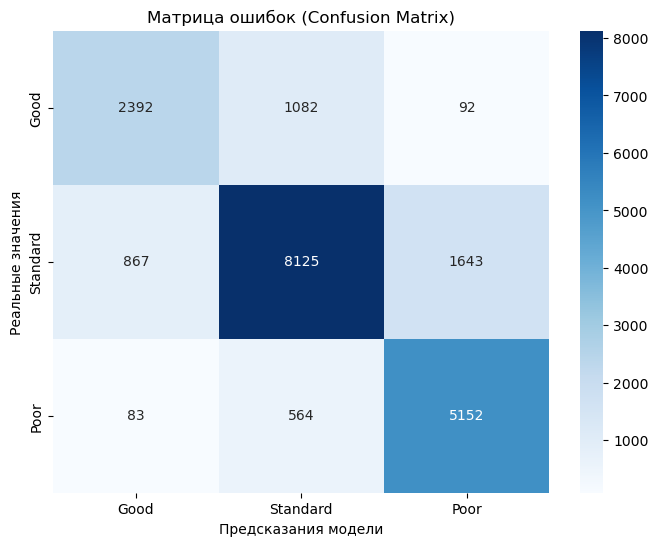

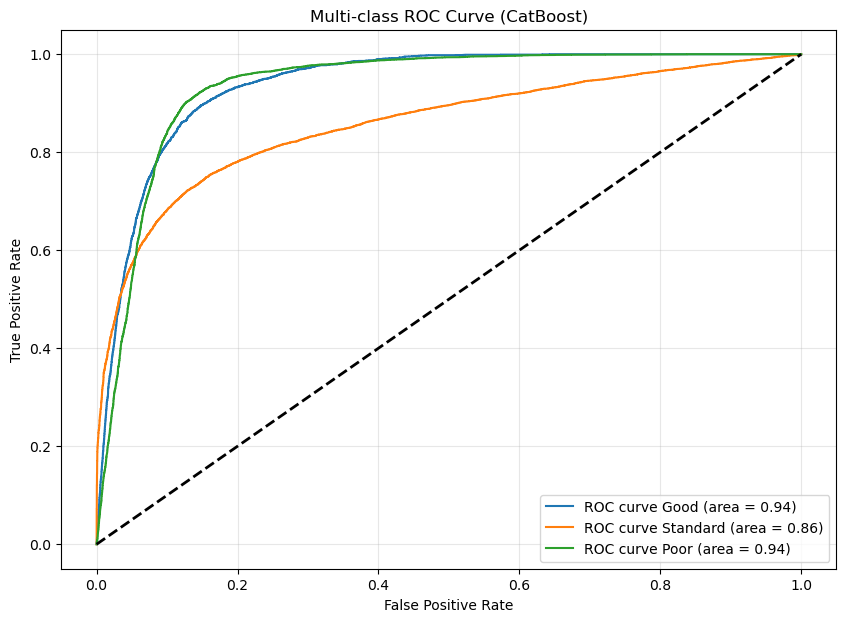

In [50]:
evaluate(model2, X_train_log, y_train_log, X_test_log, y_test_log)

## Заключение

Можно сделать вывод, что вторая модель дает результаты чуть лучше чем первая, если оценивать способность предсказывать Good и Poor, делая упор на Poor. Метрики AUC у первой и второй модели почти одинаковые.

Использование модели для новых входных данных
Для новых входных данных нужно произвести те же преобразования, что и с тренировочным датасетом, включая логарифмирование некоторых столбцов. Для преобразований достаточно будет передать исходный датасет в формате pd.DataFrame в последнюю функцию transform_data(), которая вызоывет остальные 2

In [54]:
# Для дальнейшего использования модели вынесем преобразование в отдельные функции.
# Передай исходный датасет (до любых преобразований) в transform_data() как pd.DataFrame.

def Credit_History_Age(s=str):
    try:
        y, m = map(int, s[:s.rfind(' ')].split(" Years and "))
        return y + m / 12
    except Exception:   # FIX: было bare except:
        return s

def replace_artifacts_with_nan(df, columns):
    df = df.copy()
    for col in columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')  # FIX: было errors='ignore'
    return df

def transform_data(df):
    df = df.drop(columns=['ID', 'Customer_ID', 'Name', 'SSN'])
    df['Credit_History_Age'] = df['Credit_History_Age'].apply(lambda s: Credit_History_Age(s))
    df = replace_artifacts_with_nan(df, [
        'Age', 'Annual_Income', 'Num_of_Loan', 'Num_of_Delayed_Payment',
        'Changed_Credit_Limit', 'Outstanding_Debt', 'Amount_invested_monthly', 'Monthly_Balance'
    ])
    cat_features = ['Month', 'Occupation', 'Type_of_Loan', 'Credit_Mix', 'Payment_Behaviour', 'Payment_of_Min_Amount']
    for col in cat_features:
        df[col] = df[col].astype(str)
    try:
        df = df.drop('Credit_Score', axis=1)
    except Exception:  
        pass

    lognorm_features = ['Monthly_Inhand_Salary', 'Delay_from_due_date', 'Amount_invested_monthly', 'Monthly_Balance']
    for col in lognorm_features:
        df[col] = np.log1p(df[col].clip(lower=0))

    return df


In [55]:
transform_data(train_copy).head(5)

,Month,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,...,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance
0,January,23.0,Scientist,19114.12,7.509797,3,4,3,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",...,4.0,_,809.98,26.822620,22.083333,No,49.574949,4.399563,High_spent_Small_value_payments,5.747781
1,February,23.0,Scientist,19114.12,NaN,3,4,3,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",...,4.0,Good,809.98,31.944960,NaN,No,49.574949,4.781476,Low_spent_Large_value_payments,5.654694
2,March,-500.0,Scientist,19114.12,NaN,3,4,3,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",...,4.0,Good,809.98,28.609352,22.250000,No,49.574949,4.415214,Low_spent_Medium_value_payments,5.805767
3,April,23.0,Scientist,19114.12,NaN,3,4,3,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",...,4.0,Good,809.98,31.377862,22.333333,No,49.574949,5.300605,Low_spent_Small_value_payments,5.413659
4,May,23.0,Scientist,19114.12,7.509797,3,4,3,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",...,4.0,Good,809.98,24.797347,22.416667,No,49.574949,3.747624,High_spent_Medium_value_payments,5.836240
